# Lab 1 – Partie 1 : Régression avec PyTorch (NYSE)

**Université Abdelmalek Essaadi – FST Tanger – Master MBD – Deep Learning**

**Objectif :** prédire le prix de clôture (`close`) du **jour suivant** d'une action du NYSE avec un MLP (PyTorch).

| Étape | Contenu |
|---|---|
| 1 | Analyse exploratoire (EDA) |
| 2 | Préparation des données (features, split chronologique, normalisation) |
| 3 | Architecture MLP en PyTorch |
| 4 | GridSearch (sklearn + skorch) |
| 5 | Courbes Loss/Epochs et Accuracy/Epochs + interprétation |
| 6 | Techniques de régularisation et comparaison |
| 7 | Synthèse personnelle |

**Dataset :** https://www.kaggle.com/datasets/dgawlik/nyse (on utilise `prices-split-adjusted.csv`).

> **Note sur l'« accuracy » en régression :** l'accuracy n'a pas de définition naturelle pour une variable continue.
> On utilise ici une **accuracy à tolérance** : une prédiction est « correcte » si l'erreur relative est ≤ 2 %.
> On trace aussi le **R²** pour compléter.

## 0. Installation et imports

In [2]:
# skorch = wrapper sklearn pour PyTorch (nécessaire pour utiliser GridSearchCV)
!pip install -q skorch pandas matplotlib seaborn torch numpy pandas scikit-learn


[notice] A new release of pip is available: 24.2 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
import os, glob, copy, random, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from skorch import NeuralNetRegressor

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 4)

SEED = 42
def set_seed(seed=SEED):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
set_seed()

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device :", DEVICE)

Device : cpu


## 1. Chargement des données

Le code cherche automatiquement `prices-split-adjusted.csv` :
- **Kaggle** : ajoutez le dataset `dgawlik/nyse` via *Add Data* (chemin `/kaggle/input/...`).
- **Colab / local** : placez le fichier à côté du notebook, ou dans `/content/`, ou `data/`.
  (Alternative Colab : `import kagglehub; kagglehub.dataset_download("dgawlik/nyse")`.)

In [4]:
def find_csv(name="prices-split-adjusted.csv"):
    candidates = [name, f"/content/{name}", f"data/{name}", f"/kaggle/input/nyse/{name}"]
    candidates += glob.glob(f"/kaggle/input/**/{name}", recursive=True)
    candidates += glob.glob(f"**/{name}", recursive=True)
    for p in candidates:
        if os.path.exists(p):
            return p
    raise FileNotFoundError(
        f"{name} introuvable. Ajoutez le dataset (Kaggle: Add Data / Colab: upload dans /content)."
    )

CSV_PATH = find_csv()
print("Fichier :", CSV_PATH)
df = pd.read_csv(CSV_PATH, parse_dates=["date"])
df.head()

Fichier : prices-split-adjusted.csv


,date,symbol,open,close,low,high,volume
0,2016-01-05,WLTW,123.430000,125.839996,122.309998,126.250000,2163600.0
1,2016-01-06,WLTW,125.239998,119.980003,119.940002,125.540001,2386400.0
2,2016-01-07,WLTW,116.379997,114.949997,114.930000,119.739998,2489500.0
3,2016-01-08,WLTW,115.480003,116.620003,113.500000,117.440002,2006300.0
4,2016-01-11,WLTW,117.010002,114.970001,114.089996,117.330002,1408600.0


## 2. Analyse exploratoire des données (EDA)

In [5]:
print("Dimensions :", df.shape)
print("Période    :", df["date"].min().date(), "->", df["date"].max().date())
print("Nb d'actions (symbols) :", df["symbol"].nunique())
print("\nTypes :"); print(df.dtypes)
print("\nValeurs manquantes :"); print(df.isna().sum())
print("\nDoublons (date, symbol) :", df.duplicated(["date", "symbol"]).sum())
df.describe().T

Dimensions : (851264, 7)
Période    : 2010-01-04 -> 2016-12-30
Nb d'actions (symbols) : 501

Types :
date      datetime64[us]
symbol               str
open             float64
close            float64
low              float64
high             float64
volume           float64
dtype: object

Valeurs manquantes :
date      0
symbol    0
open      0
close     0
low       0
high      0
volume    0
dtype: int64

Doublons (date, symbol) : 0


,count,mean,min,25%,50%,75%,max,std
date,851264,2013-07-21 02:56:29.294038,2010-01-04 00:00:00,2011-10-19 00:00:00,2013-08-02 00:00:00,2015-04-24 00:00:00,2016-12-30 00:00:00,NaN
open,851264.0,64.993618,1.66,31.27,48.459999,75.120003,1584.439941,75.203893
close,851264.0,65.011913,1.59,31.292776,48.48,75.139999,1578.130005,75.201216
low,851264.0,64.336541,1.5,30.940001,47.970001,74.400002,1549.939941,74.459518
high,851264.0,65.639748,1.81,31.620001,48.959999,75.849998,1600.930054,75.906861
volume,851264.0,5415112.640027,0.0,1221500.0,2476250.0,5222500.0,859643400.0,12494681.433081


count     501.000000
mean     1699.129741
std       253.731238
min       126.000000
25%      1762.000000
50%      1762.000000
75%      1762.000000
max      1762.000000
dtype: float64


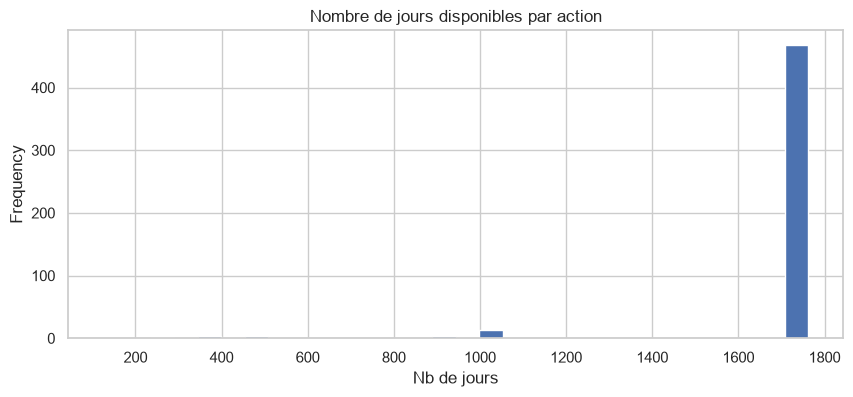

In [6]:
# Nombre d'observations par action
counts = df.groupby("symbol").size()
print(counts.describe())
fig, ax = plt.subplots()
counts.plot.hist(bins=30, ax=ax)
ax.set_title("Nombre de jours disponibles par action"); ax.set_xlabel("Nb de jours")
plt.show()

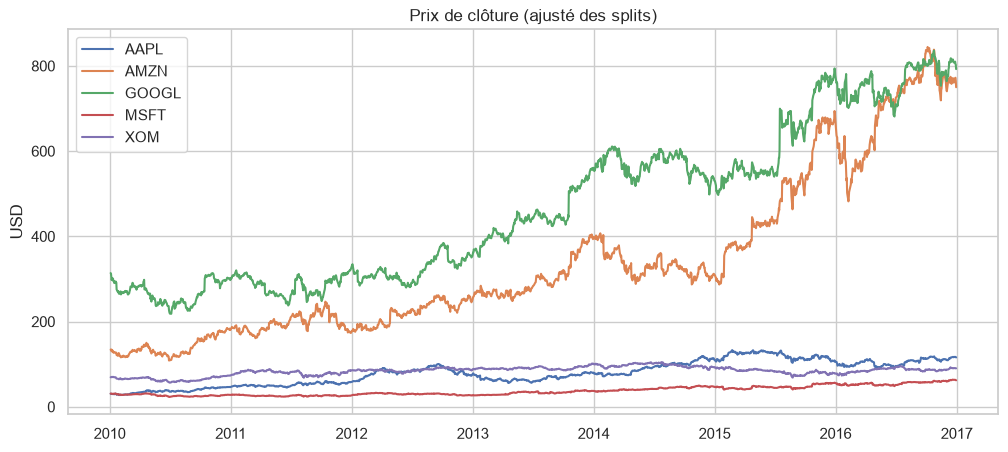

In [7]:
# Évolution du prix de clôture pour quelques actions connues
wanted = ["AAPL", "AMZN", "GOOGL", "MSFT", "XOM"]
shown = [s for s in wanted if s in df["symbol"].unique()] or list(df["symbol"].unique()[:5])

fig, ax = plt.subplots(figsize=(12, 5))
for s in shown:
    d = df[df["symbol"] == s]
    ax.plot(d["date"], d["close"], label=s)
ax.set_title("Prix de clôture (ajusté des splits)"); ax.set_ylabel("USD"); ax.legend()
plt.show()

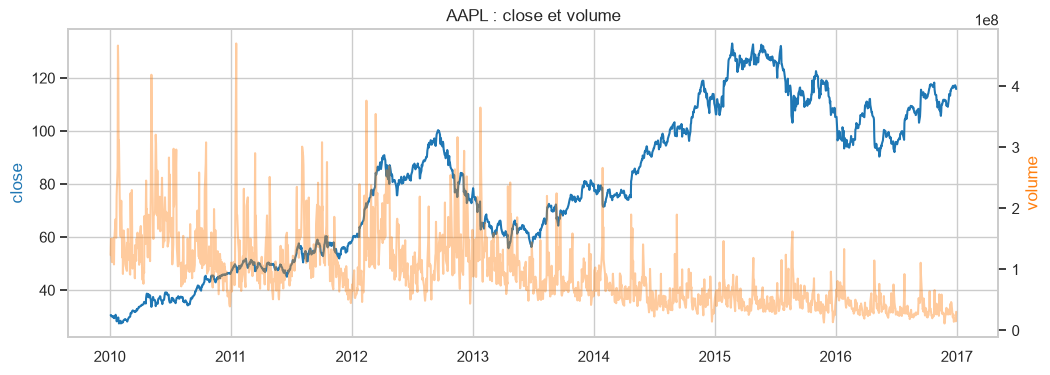

In [8]:
# Prix vs volume pour une action
s0 = shown[0]
d = df[df["symbol"] == s0]
fig, ax1 = plt.subplots(figsize=(12, 4))
ax1.plot(d["date"], d["close"], color="tab:blue"); ax1.set_ylabel("close", color="tab:blue")
ax2 = ax1.twinx(); ax2.plot(d["date"], d["volume"], color="tab:orange", alpha=.4)
ax2.set_ylabel("volume", color="tab:orange"); ax2.grid(False)
ax1.set_title(f"{s0} : close et volume")
plt.show()

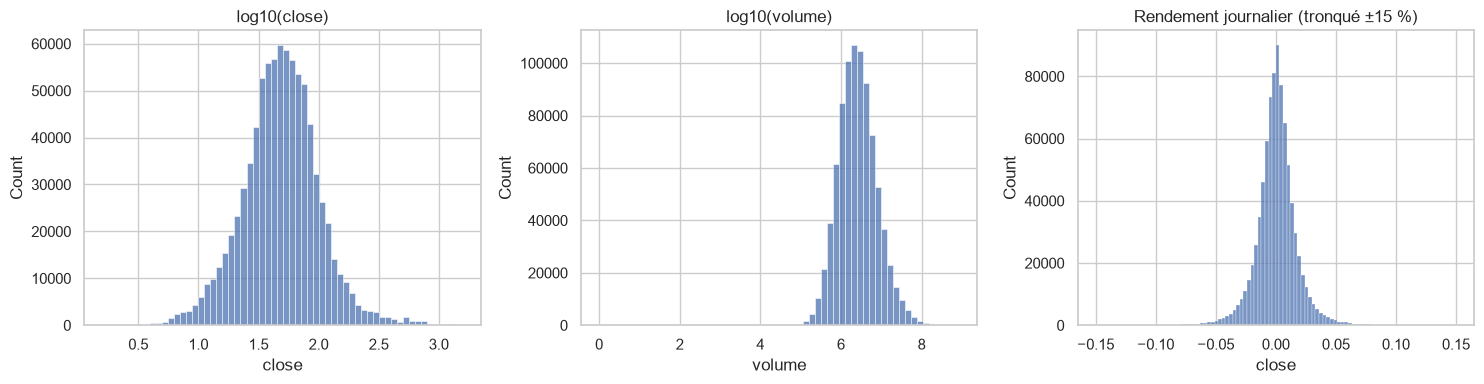

Skewness :
 open       7.240055
close      7.236975
low        7.239734
high       7.236056
volume    13.132746
dtype: float64


In [9]:
# Distributions (échelle log car très asymétriques)
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
sns.histplot(np.log10(df["close"]), bins=60, ax=axes[0]); axes[0].set_title("log10(close)")
sns.histplot(np.log10(df["volume"] + 1), bins=60, ax=axes[1]); axes[1].set_title("log10(volume)")
ret = df.sort_values(["symbol", "date"]).groupby("symbol")["close"].pct_change().dropna()
sns.histplot(ret.clip(-0.15, 0.15), bins=100, ax=axes[2]); axes[2].set_title("Rendement journalier (tronqué ±15 %)")
plt.tight_layout(); plt.show()
print("Skewness :\n", df[["open", "close", "low", "high", "volume"]].skew())

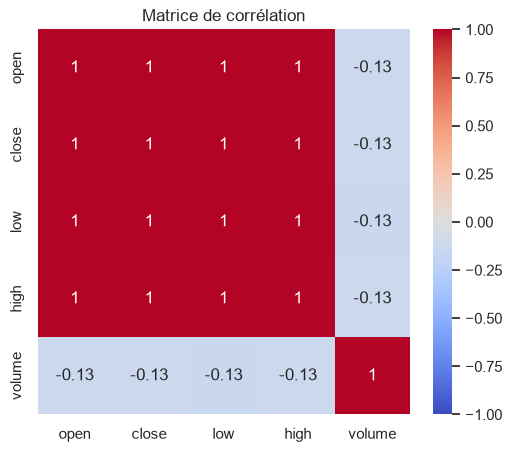

In [10]:
# Corrélations
num_cols = ["open", "close", "low", "high", "volume"]
fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(df[num_cols].corr(), annot=True, cmap="coolwarm", vmin=-1, vmax=1, ax=ax)
ax.set_title("Matrice de corrélation")
plt.show()

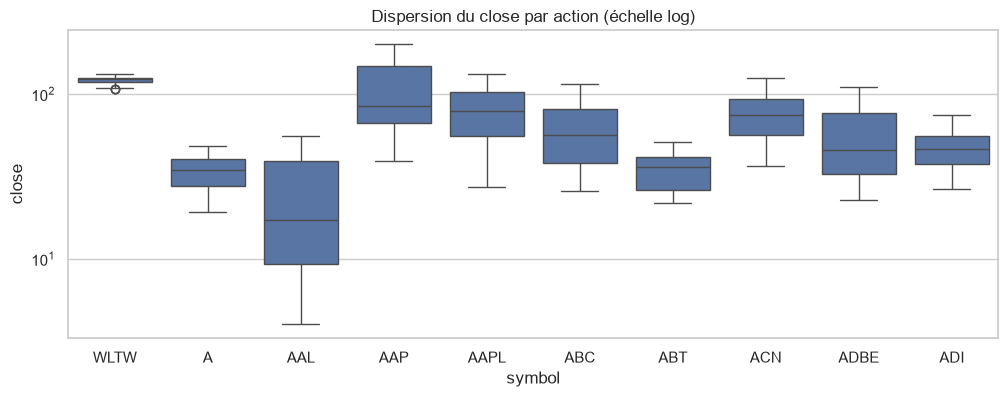

In [11]:
# Valeurs aberrantes : boxplot de quelques actions (échelle log)
sample10 = list(df["symbol"].unique()[:10])
fig, ax = plt.subplots(figsize=(12, 4))
sns.boxplot(data=df[df["symbol"].isin(sample10)], x="symbol", y="close", ax=ax)
ax.set_yscale("log"); ax.set_title("Dispersion du close par action (échelle log)")
plt.show()

**À retenir de l'EDA :**
- Pas de valeurs manquantes / doublons 
- `open`, `high`, `low`, `close` sont quasi parfaitement corrélés → le prix du jour est un très bon prédicteur du prix du lendemain.
- Les prix varient énormément d'une action à l'autre (échelle) → normalisation indispensable.
- Le volume est très asymétrique → transformation `log1p`.

## 3. Préparation des données

**Choix :**
- **Cible** : `close` du jour suivant (`shift(-1)` par action).
- **Features** : `open, high, low, close, log_volume`, 3 retards du `close`, moyenne mobile 5 jours, rendement du jour.
- **Sous-échantillon** de `N_SYMBOLS` actions pour que le GridSearch reste rapide (mettre `None` pour tout utiliser).
- **Split chronologique** (train / validation / test) : *jamais aléatoire* sur une série temporelle, sinon fuite d'information du futur.
- **Normalisation** (`StandardScaler`) ajustée **uniquement sur le train**.

In [12]:
N_SYMBOLS = 30          # None = toutes les actions (GridSearch beaucoup plus long)

symbols = sorted(df["symbol"].unique())
if N_SYMBOLS is not None:
    rng = np.random.RandomState(SEED)
    symbols = sorted(rng.choice(symbols, size=N_SYMBOLS, replace=False))
print("Actions retenues :", symbols)

data = df[df["symbol"].isin(symbols)].sort_values(["symbol", "date"]).copy()
g = data.groupby("symbol")["close"]

data["target"]     = g.shift(-1)                       # close de demain
data["close_lag1"] = g.shift(1)
data["close_lag2"] = g.shift(2)
data["close_lag3"] = g.shift(3)
data["ma5"]        = g.transform(lambda s: s.rolling(5).mean())
data["ret1"]       = g.pct_change()
data["log_volume"] = np.log1p(data["volume"])

FEATURES = ["open", "high", "low", "close", "log_volume",
            "close_lag1", "close_lag2", "close_lag3", "ma5", "ret1"]

data = data.dropna(subset=FEATURES + ["target"]).reset_index(drop=True)
data = data.sort_values("date").reset_index(drop=True)   # tri par date (utile pour TimeSeriesSplit)
print("Taille finale :", data.shape)

Actions retenues : [np.str_('ADI'), np.str_('AMAT'), np.str_('BSX'), np.str_('CAG'), np.str_('CB'), np.str_('CFG'), np.str_('COF'), np.str_('COL'), np.str_('DE'), np.str_('EOG'), np.str_('GD'), np.str_('HAR'), np.str_('LOW'), np.str_('MTB'), np.str_('NSC'), np.str_('PEP'), np.str_('PHM'), np.str_('PVH'), np.str_('PXD'), np.str_('RSG'), np.str_('SNA'), np.str_('SO'), np.str_('SWKS'), np.str_('ULTA'), np.str_('VFC'), np.str_('WY'), np.str_('XLNX'), np.str_('XOM'), np.str_('YHOO'), np.str_('ZBH')]
Taille finale : (51452, 14)


In [13]:
# Split chronologique 70 % / 15 % / 15 % sur les dates
dates = np.sort(data["date"].unique())
cut_val  = dates[int(0.70 * len(dates))]
cut_test = dates[int(0.85 * len(dates))]

train_df = data[data["date"] <  cut_val]
val_df   = data[(data["date"] >= cut_val) & (data["date"] < cut_test)]
test_df  = data[data["date"] >= cut_test]
print(f"Train : {len(train_df):>7}  ({train_df.date.min().date()} -> {train_df.date.max().date()})")
print(f"Val   : {len(val_df):>7}  ({val_df.date.min().date()} -> {val_df.date.max().date()})")
print(f"Test  : {len(test_df):>7}  ({test_df.date.min().date()} -> {test_df.date.max().date()})")

# Normalisation : fit sur le train uniquement
scaler_X = StandardScaler().fit(train_df[FEATURES])
scaler_y = StandardScaler().fit(train_df[["target"]])

def prep(d):
    X = scaler_X.transform(d[FEATURES]).astype(np.float32)
    y = scaler_y.transform(d[["target"]]).astype(np.float32)       # cible normalisée (n, 1)
    y_raw = d["target"].values                                     # cible en USD (pour les métriques)
    return X, y, y_raw

X_train, y_train, y_train_raw = prep(train_df)
X_val,   y_val,   y_val_raw   = prep(val_df)
X_test,  y_test,  y_test_raw  = prep(test_df)
print("X_train :", X_train.shape, "| y_train :", y_train.shape)

Train :   35641  (2010-01-08 -> 2014-11-24)
Val   :    7891  (2014-11-25 -> 2015-12-11)
Test  :    7920  (2015-12-14 -> 2016-12-29)
X_train : (35641, 10) | y_train : (35641, 1)


### Métriques et baseline naïve

- **RMSE / MAE / R²** calculés en **USD** (après dénormalisation).
- **Accuracy ±2 %** : proportion de prédictions dont l'erreur relative est ≤ 2 %.
- **Baseline naïve** : prédire que le prix de demain = prix d'aujourd'hui. Un bon modèle doit au moins s'en approcher / la battre.

In [14]:
TOL = 0.02

def inv_y(y_scaled):
    return scaler_y.inverse_transform(np.asarray(y_scaled).reshape(-1, 1)).ravel()

def tol_accuracy(y_true, y_pred, tol=TOL):
    return float(np.mean(np.abs(y_pred - y_true) / np.abs(y_true) <= tol))

def regression_metrics(y_true, y_pred):
    return {
        "RMSE": float(np.sqrt(mean_squared_error(y_true, y_pred))),
        "MAE":  float(mean_absolute_error(y_true, y_pred)),
        "R2":   float(r2_score(y_true, y_pred)),
        f"Acc±{int(TOL*100)}%": tol_accuracy(y_true, y_pred),
    }

naive_test = regression_metrics(y_test_raw, test_df["close"].values)
print("Baseline naïve (close demain = close aujourd'hui), test :")
pd.Series(naive_test).round(4)

Baseline naïve (close demain = close aujourd'hui), test :


RMSE      1.5663
MAE       0.9000
R2        0.9989
Acc±2%    0.8403
dtype: float64

## 4. Architecture du réseau (MLP PyTorch)

MLP paramétrable : nombre de couches cachées, taille, **dropout** et **BatchNorm** optionnels (utilisés plus tard pour la régularisation).
Sortie : 1 neurone linéaire (régression). Perte : **MSE**.

In [15]:
class MLP(nn.Module):
    def __init__(self, input_dim, hidden_dim=64, n_layers=2, dropout=0.0, batchnorm=False):
        super().__init__()
        layers, d = [], input_dim
        for _ in range(n_layers):
            layers.append(nn.Linear(d, hidden_dim))
            if batchnorm:
                layers.append(nn.BatchNorm1d(hidden_dim))
            layers.append(nn.ReLU())
            if dropout > 0:
                layers.append(nn.Dropout(dropout))
            d = hidden_dim
        layers.append(nn.Linear(d, 1))
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x)

print(MLP(input_dim=len(FEATURES)))

MLP(
  (net): Sequential(
    (0): Linear(in_features=10, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=64, bias=True)
    (3): ReLU()
    (4): Linear(in_features=64, out_features=1, bias=True)
  )
)


## 5. GridSearch des hyper-paramètres (sklearn + skorch)

`skorch.NeuralNetRegressor` enveloppe notre module PyTorch pour le rendre compatible avec `GridSearchCV`.

- **Validation croisée temporelle** : `TimeSeriesSplit` (les plis de validation sont toujours *après* les plis d'entraînement).
- **Hyper-paramètres explorés** : learning rate, optimiseur (Adam, RMSprop, SGD+momentum), nombre d'epochs, taille et profondeur du réseau.
- Le GridSearch utilise **uniquement le train** (le test n'est jamais vu).

In [16]:
net = NeuralNetRegressor(
    module=MLP,
    module__input_dim=X_train.shape[1],
    criterion=nn.MSELoss,
    optimizer=torch.optim.Adam,
    lr=1e-3,
    max_epochs=20,
    batch_size=512,
    train_split=None,      # la validation est gérée par GridSearchCV
    verbose=0,
    device=DEVICE,
)

param_grid = [
    {   # Adam et RMSprop
        "optimizer": [torch.optim.Adam, torch.optim.RMSprop],
        "lr": [1e-3, 1e-2],
        "max_epochs": [20, 40],
        "module__hidden_dim": [32, 64],
        "module__n_layers": [2, 3],
    },
    {   # SGD avec momentum
        "optimizer": [torch.optim.SGD],
        "optimizer__momentum": [0.9],
        "lr": [1e-3, 1e-2],
        "max_epochs": [20, 40],
        "module__hidden_dim": [32, 64],
        "module__n_layers": [2, 3],
    },
]

gs = GridSearchCV(
    net, param_grid,
    cv=TimeSeriesSplit(n_splits=3),
    scoring="neg_mean_squared_error",
    refit=False,           # on ré-entraîne nous-mêmes avec notre boucle (pour tracer les courbes)
    n_jobs=1, verbose=1,
)
gs.fit(X_train, y_train)

Fitting 3 folds for each of 48 candidates, totalling 144 fits


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.","<class 'skorc...nput_dim=10, )"
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","[{'lr': [0.001, 0.01], 'max_epochs': [20, 40], 'module__hidden_dim': [32, 64], 'module__n_layers': [2, 3], ...}, {'lr': [0.001, 0.01], 'max_epochs': [20, 40], 'module__hidden_dim': [32, 64], 'module__n_layers': [2, 3], ...}]"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'neg_mean_squared_error'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",False
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strate

In [18]:
print("Meilleurs hyper-paramètres :")
for k, v in gs.best_params_.items():
    print(f"  {k:22s}: {getattr(v, '__name__', v)}")
print("Meilleur score CV (-MSE normalisée) :", round(gs.best_score_, 5))

res = pd.DataFrame(gs.cv_results_)
res["optimizer_name"] = res["param_optimizer"].apply(lambda o: o.__name__)
cols = ["optimizer_name", "param_lr", "param_max_epochs", "param_module__hidden_dim",
        "param_module__n_layers", "mean_test_score", "std_test_score", "rank_test_score"]
res.sort_values("rank_test_score")[cols].head(10).reset_index(drop=True)

Meilleurs hyper-paramètres :
  lr                    : 0.001
  max_epochs            : 40
  module__hidden_dim    : 32
  module__n_layers      : 2
  optimizer             : Adam
Meilleur score CV (-MSE normalisée) : -0.00131


,optimizer_name,param_lr,param_max_epochs,param_module__hidden_dim,param_module__n_layers,mean_test_score,std_test_score,rank_test_score
0,Adam,0.001,40,32,2,-0.001312,0.000289,1
1,Adam,0.010,20,64,2,-0.001316,0.000356,2
2,Adam,0.001,40,32,3,-0.001351,0.000270,3
3,Adam,0.001,20,64,2,-0.001358,0.000243,4
4,Adam,0.001,20,32,3,-0.001363,0.000240,5
5,Adam,0.001,40,64,2,-0.001373,0.000349,6
6,SGD,0.010,40,64,2,-0.001379,0.000223,7
7,Adam,0.001,20,32,2,-0.001427,0.000272,8
8,Adam,0.001,20,64,3,-0.001435,0.000356,9
9,Adam,0.001,40,64,3,-0.001440,0.000326,10


## 6. Entraînement du meilleur modèle et courbes Loss / Accuracy

Boucle d'entraînement PyTorch « maison » qui enregistre à chaque epoch :
- la **loss** (MSE sur cibles normalisées),
- l'**accuracy ±2 %** et le **R²** (en USD),

pour le **train** et le **test** (le *test* sert uniquement à tracer les courbes ; la sélection d'epoch par early stopping, quand elle est utilisée, se base sur la **validation**).

In [19]:
def build_optimizer(opt_cls, params, lr, weight_decay=0.0, momentum=0.9):
    kwargs = dict(lr=lr, weight_decay=weight_decay)
    if opt_cls is torch.optim.SGD:
        kwargs["momentum"] = momentum
    return opt_cls(params, **kwargs)

@torch.no_grad()
def predict(model, X):
    model.eval()
    out = []
    for i in range(0, len(X), 8192):
        out.append(model(torch.from_numpy(X[i:i+8192]).to(DEVICE)).cpu().numpy())
    return np.vstack(out)

def evaluate(model, X, y_scaled, y_raw):
    p = predict(model, X)
    loss = float(np.mean((p - y_scaled) ** 2))
    p_usd = inv_y(p)
    return loss, tol_accuracy(y_raw, p_usd), float(r2_score(y_raw, p_usd))

def train_model(hidden_dim, n_layers, opt_cls, lr, epochs, momentum=0.9,
                dropout=0.0, batchnorm=False, weight_decay=0.0, l1_lambda=0.0,
                patience=None, batch_size=512, seed=SEED):
    set_seed(seed)
    model = MLP(X_train.shape[1], hidden_dim, n_layers, dropout, batchnorm).to(DEVICE)
    opt = build_optimizer(opt_cls, model.parameters(), lr, weight_decay, momentum)
    crit = nn.MSELoss()

    loader = DataLoader(TensorDataset(torch.from_numpy(X_train), torch.from_numpy(y_train)),
                        batch_size=batch_size, shuffle=True)   # shuffle des mini-batchs : OK (le split reste chronologique)

    hist = {k: [] for k in ["train_loss", "val_loss", "test_loss",
                            "train_acc", "val_acc", "test_acc",
                            "train_r2", "val_r2", "test_r2"]}
    best_val, best_state, best_epoch, wait = np.inf, None, 0, 0

    for ep in range(1, epochs + 1):
        model.train()
        for xb, yb in loader:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            opt.zero_grad()
            loss = crit(model(xb), yb)
            if l1_lambda > 0:   # régularisation L1 manuelle
                loss = loss + l1_lambda * sum(p.abs().sum() for n, p in model.named_parameters() if "weight" in n)
            loss.backward()
            opt.step()

        for name, (X, y, yr) in {"train": (X_train, y_train, y_train_raw),
                                 "val":   (X_val,   y_val,   y_val_raw),
                                 "test":  (X_test,  y_test,  y_test_raw)}.items():
            l, a, r = evaluate(model, X, y, yr)
            hist[f"{name}_loss"].append(l); hist[f"{name}_acc"].append(a); hist[f"{name}_r2"].append(r)

        if patience is not None:                       # early stopping sur la VALIDATION
            if hist["val_loss"][-1] < best_val - 1e-6:
                best_val, best_epoch, wait = hist["val_loss"][-1], ep, 0
                best_state = copy.deepcopy(model.state_dict())
            else:
                wait += 1
                if wait >= patience:
                    break

    if patience is not None and best_state is not None:
        model.load_state_dict(best_state)
    else:
        best_epoch = len(hist["train_loss"])
    return model, hist, best_epoch

def plot_history(hist, title="", best_epoch=None):
    fig, axes = plt.subplots(1, 3, figsize=(17, 4))
    ep = range(1, len(hist["train_loss"]) + 1)
    for ax, key, lab in zip(axes, ["loss", "acc", "r2"],
                            ["Loss (MSE normalisée)", f"Accuracy ±{int(TOL*100)} %", "R²"]):
        ax.plot(ep, hist[f"train_{key}"], label="Train")
        ax.plot(ep, hist[f"test_{key}"], label="Test", linestyle="--")
        if best_epoch and best_epoch < len(ep):
            ax.axvline(best_epoch, color="gray", linestyle=":", label="Meilleure epoch")
        ax.set_xlabel("Epochs"); ax.set_ylabel(lab); ax.set_title(f"{lab} / Epochs"); ax.legend()
    axes[0].set_yscale("log")
    fig.suptitle(title); plt.tight_layout(); plt.show()

{'hidden_dim': 32, 'n_layers': 2, 'opt_cls': 'Adam', 'lr': 0.001, 'epochs': 40, 'momentum': 0.9}


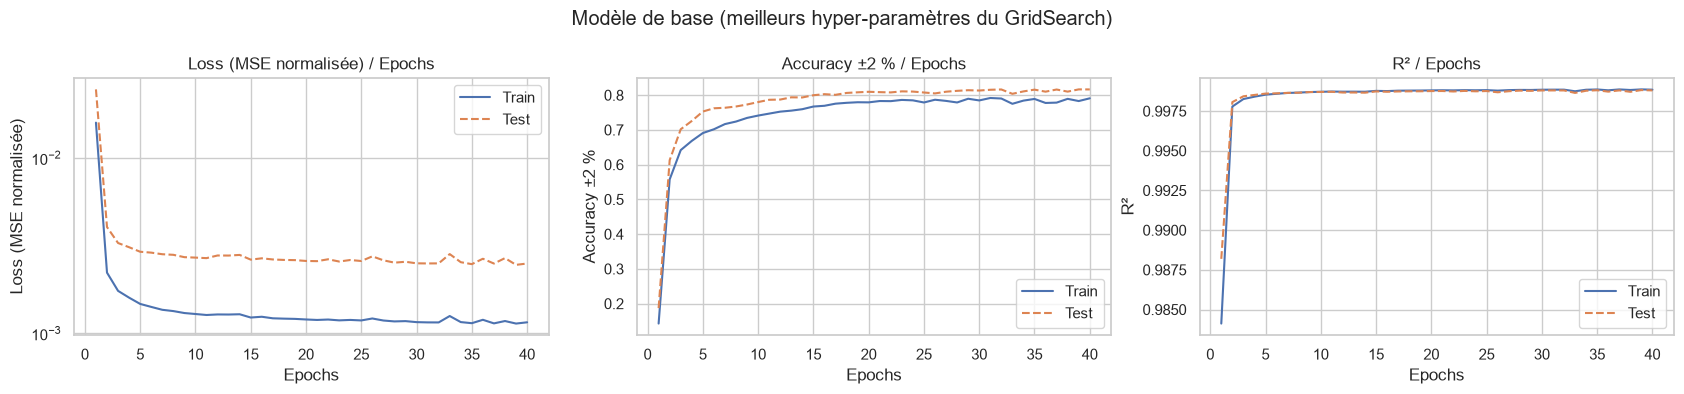

In [20]:
bp = gs.best_params_
BEST = dict(
    hidden_dim=bp["module__hidden_dim"], n_layers=bp["module__n_layers"],
    opt_cls=bp["optimizer"], lr=bp["lr"], epochs=bp["max_epochs"],
    momentum=bp.get("optimizer__momentum", 0.9),
)
print({k: getattr(v, "__name__", v) for k, v in BEST.items()})

model_base, hist_base, _ = train_model(**BEST)
plot_history(hist_base, title="Modèle de base (meilleurs hyper-paramètres du GridSearch)")

In [21]:
def final_metrics(model, name):
    rows = {}
    for split, (X, y_raw) in {"train": (X_train, y_train_raw), "test": (X_test, y_test_raw)}.items():
        m = regression_metrics(y_raw, inv_y(predict(model, X)))
        rows.update({f"{split}_{k}": v for k, v in m.items()})
    return pd.Series(rows, name=name)

pd.concat([final_metrics(model_base, "MLP de base"),
           pd.Series({f"test_{k}": v for k, v in naive_test.items()}, name="Baseline naïve")], axis=1).round(4)

,MLP de base,Baseline naïve
train_RMSE,1.1276,NaN
train_MAE,0.6820,NaN
train_R2,0.9988,NaN
train_Acc±2%,0.7908,NaN
test_RMSE,1.6588,1.5663
test_MAE,0.9756,0.9000
test_R2,0.9988,0.9989
test_Acc±2%,0.8164,0.8403


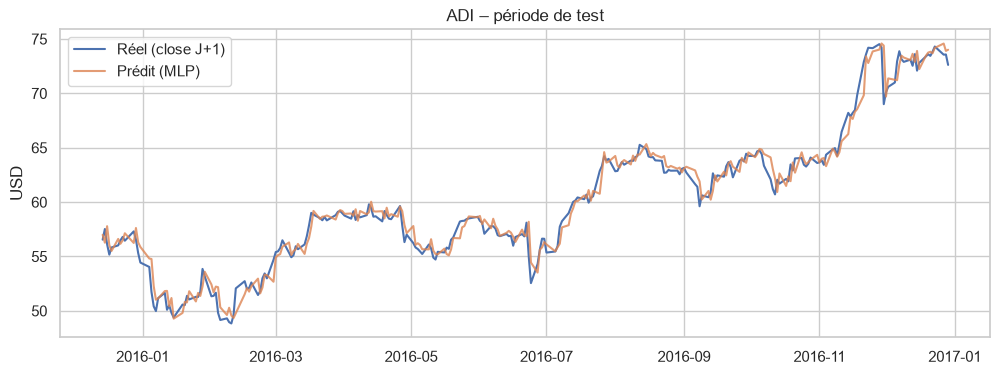

In [22]:
# Prédictions vs réalité sur la période de test pour une action
sym = symbols[0]
mask = (test_df["symbol"] == sym).values
d_sym = test_df[mask]
pred_sym = inv_y(predict(model_base, X_test[mask]))

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(d_sym["date"], y_test_raw[mask], label="Réel (close J+1)")
ax.plot(d_sym["date"], pred_sym, label="Prédit (MLP)", alpha=.8)
ax.set_title(f"{sym} – période de test"); ax.set_ylabel("USD"); ax.legend()
plt.show()

### Interprétation des courbes (à rédiger avec VOS résultats)

Points à commenter :
1. **Loss / Epochs** : la loss train et test décroissent-elles ? Se stabilisent-elles ? Y a-t-il un écart croissant entre les deux (→ *overfitting*) ou les deux restent élevées (→ *underfitting*) ?
2. **Accuracy / Epochs** (et R²) : l'accuracy à ±2 % progresse-t-elle ? Est-elle comparable entre train et test ?
3. **Décalage train/test** : le test est une période *future* (régime de marché possiblement différent, prix hors de la plage vue en train) → un écart peut venir de ce *distribution shift* et pas seulement du surapprentissage.
4. **Comparaison avec la baseline naïve** : le MLP fait-il mieux que « demain = aujourd'hui » ? Si non, expliquez pourquoi (le prix du jour contient presque toute l'information).

## 7. Techniques de régularisation et comparaison

On garde les **mêmes hyper-paramètres** que le modèle de base et on ajoute, séparément puis combinées :

| Technique | Principe |
|---|---|
| **Dropout** | désactive aléatoirement des neurones pendant l'entraînement |
| **L2 (weight decay)** | pénalise la norme des poids |
| **L1** | pénalise la somme des valeurs absolues des poids (sparsité) |
| **BatchNorm** | normalise les activations de chaque couche |
| **Early stopping** | arrête l'entraînement quand la loss de validation ne s'améliore plus |
| **Combinaison** | Dropout + L2 + Early stopping |

Les modèles avec early stopping disposent d'un budget de `3 × epochs` avec une patience de 10.

In [23]:
E = BEST["epochs"]
base_kw = {k: v for k, v in BEST.items() if k != "epochs"}

experiments = {
    "Base":              dict(epochs=E),
    "Dropout 0.2":       dict(epochs=E, dropout=0.2),
    "L2 (wd=1e-3)":      dict(epochs=E, weight_decay=1e-3),
    "L1 (1e-5)":         dict(epochs=E, l1_lambda=1e-5),
    "BatchNorm":         dict(epochs=E, batchnorm=True),
    "Early stopping":    dict(epochs=3 * E, patience=10),
    "Dropout+L2+ES":     dict(epochs=3 * E, patience=10, dropout=0.1, weight_decay=1e-4),
}

models, hists, best_eps, rows = {}, {}, {}, []
for name, kw in experiments.items():
    print(f"Entraînement : {name} ...")
    m, h, be = train_model(**base_kw, **kw)
    models[name], hists[name], best_eps[name] = m, h, be
    rows.append(final_metrics(m, name))

comparison = pd.concat(rows + [pd.Series({f"test_{k}": v for k, v in naive_test.items()}, name="Baseline naïve")], axis=1).T
comparison["epochs_utilisées"] = pd.Series(best_eps)
comparison.round(4)

Entraînement : Base ...
Entraînement : Dropout 0.2 ...
Entraînement : L2 (wd=1e-3) ...
Entraînement : L1 (1e-5) ...
Entraînement : BatchNorm ...
Entraînement : Early stopping ...
Entraînement : Dropout+L2+ES ...


,train_RMSE,train_MAE,train_R2,train_Acc±2%,test_RMSE,test_MAE,test_R2,test_Acc±2%,epochs_utilisées
Base,1.1276,0.6820,0.9988,0.7908,1.6588,0.9756,0.9988,0.8164,40.0
Dropout 0.2,2.7146,1.7094,0.9933,0.4195,5.2113,3.3917,0.9882,0.3336,40.0
L2 (wd=1e-3),1.1384,0.6892,0.9988,0.7740,1.6899,0.9754,0.9988,0.8163,40.0
L1 (1e-5),1.1270,0.6801,0.9988,0.7908,1.6568,0.9743,0.9988,0.8177,40.0
BatchNorm,1.5757,1.0840,0.9977,0.5625,2.5980,1.7500,0.9971,0.5465,40.0
Early stopping,1.0950,0.6570,0.9989,0.7982,1.6115,0.9344,0.9989,0.8259,56.0
Dropout+L2+ES,1.3356,0.9445,0.9984,0.6082,1.8204,1.1506,0.9986,0.7169,10.0
Baseline naïve,NaN,NaN,NaN,NaN,1.5663,0.9000,0.9989,0.8403,NaN


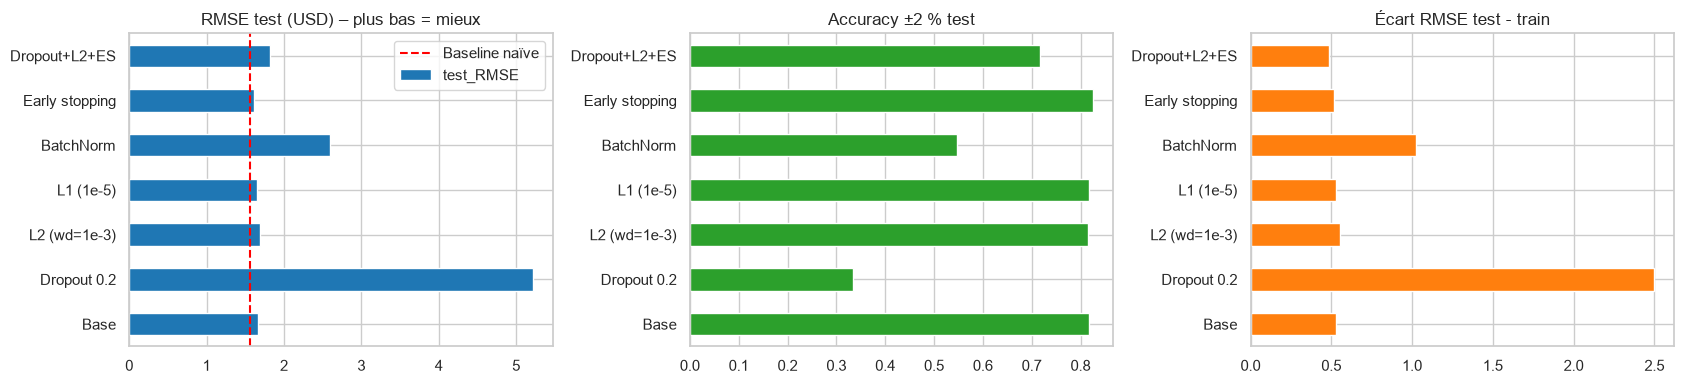

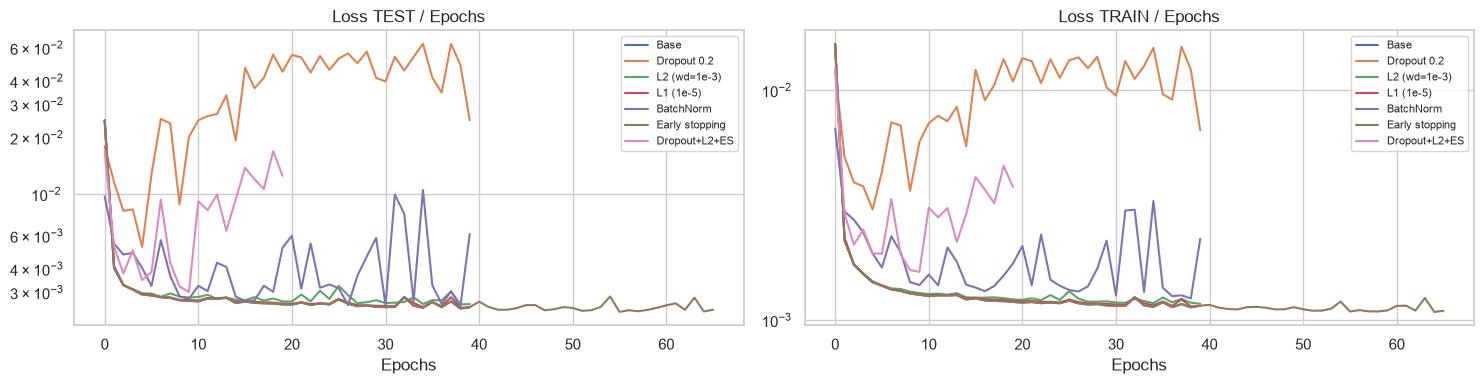

In [24]:
# Gap train/test (indicateur de surapprentissage) et visualisation
cmp = comparison.drop(index="Baseline naïve").copy()
cmp["gap_RMSE (test - train)"] = cmp["test_RMSE"] - cmp["train_RMSE"]

fig, axes = plt.subplots(1, 3, figsize=(17, 4))
cmp["test_RMSE"].plot.barh(ax=axes[0], color="tab:blue");  axes[0].set_title("RMSE test (USD) – plus bas = mieux")
axes[0].axvline(naive_test["RMSE"], color="red", linestyle="--", label="Baseline naïve"); axes[0].legend()
cmp[f"test_Acc±{int(TOL*100)}%"].plot.barh(ax=axes[1], color="tab:green"); axes[1].set_title(f"Accuracy ±{int(TOL*100)} % test")
cmp["gap_RMSE (test - train)"].plot.barh(ax=axes[2], color="tab:orange"); axes[2].set_title("Écart RMSE test - train")
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, 2, figsize=(15, 4))
for name, h in hists.items():
    axes[0].plot(h["test_loss"], label=name)
    axes[1].plot(h["train_loss"], label=name)
axes[0].set_title("Loss TEST / Epochs"); axes[1].set_title("Loss TRAIN / Epochs")
for ax in axes: ax.set_yscale("log"); ax.set_xlabel("Epochs"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

Meilleur modèle régularisé : Early stopping


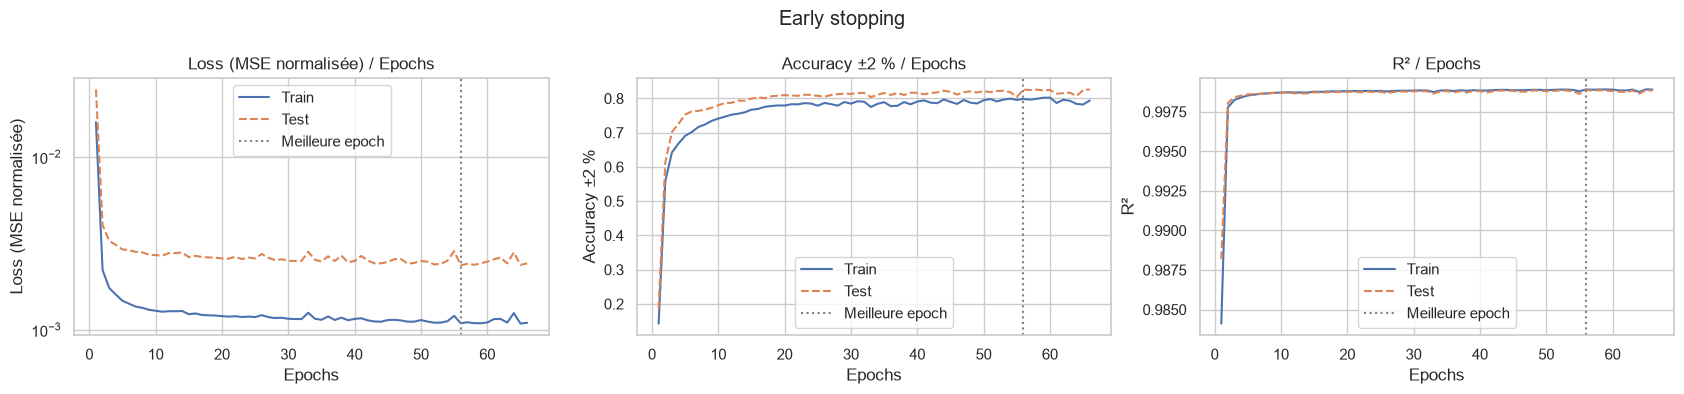

In [25]:
# Courbes détaillées du meilleur modèle régularisé (selon le RMSE test)
best_reg = cmp.drop(index="Base")["test_RMSE"].idxmin()
print("Meilleur modèle régularisé :", best_reg)
plot_history(hists[best_reg], title=f"{best_reg}", best_epoch=best_eps[best_reg])

### Comparaison avec le premier modèle (à rédiger avec VOS résultats)

- Quelle technique améliore (ou dégrade) le RMSE / l'accuracy **test** par rapport à `Base` ?
- L'**écart train/test** diminue-t-il avec la régularisation ?
- Pourquoi la régularisation apporte-t-elle peu (ou beaucoup) ici ? (modèle petit, peu de features, problème quasi-linéaire dominé par le prix du jour…)
- Quelle configuration retenez-vous au final et pourquoi ?

## 8. Synthèse personnelle

*(À rédiger par vos soins : ce que vous avez appris pendant ce lab. Pistes :)*
- Prise en main de PyTorch : `nn.Module`, `DataLoader`, boucle d'entraînement, optimiseurs, `state_dict`.
- Différence classification / régression (perte, sortie, métriques) et pourquoi l'« accuracy » doit être redéfinie en régression.
- Importance du **split chronologique** et de la normalisation ajustée sur le train seul (éviter la fuite de données).
- Rôle du GridSearch (via skorch) et son coût de calcul ; validation croisée temporelle.
- Effet de chaque technique de régularisation, intérêt de comparer à une **baseline naïve**.
- Limites : prédiction de prix boursiers, régime de marché, pas de garantie en conditions réelles.